# 03 · Baselines: random, JET-only, Isolation Forest, LOF

**Workflow step: Step 3 of Figure 1 in the proposal — first part** ("Workflow of the proposed approach and the evaluation").

**Where we are.** Notebook 01 (Step 1) reduced the ledger to one row per journal entry and built the four JET flags (`meta.parquet`). Their union holds 24,183 entries and 798 of the 850 anomalies: recall 93.9 %, precision only 3.3 %. The number of rules hit (`h`) orders only the top of that list; 21,387 entries hit exactly one rule (precision 2.5 %). Notebook 02 (Step 2 a) turned every entry into a fixed-length vector (`X_onehot.npz`, 140 columns stored, 131 in the main setting). Scalers are fitted per fiscal year, feature groups are chosen per run by name (`fe.ABLATIONS`), and LOF needs k ≥ 37 because up to 36 entries share the same vector.

## Purpose of this notebook
Step 3 builds the baselines that the proposed approach (Step 4) must beat. This notebook covers the first part of them on the one-hot encoding. It answers two questions: how far do the rules alone get, and how far does an unsupervised model alone get, under the same review budgets? The autoencoder, H1, H2 and the embedding encoding follow in notebook 05.

Where each goal is met:
1. **Load the inputs safely**: meta and the main-setting matrix, with the row-order check, split by fiscal year (D6). Section 1.
2. **LOF grid vs identical vectors**: confirm that every k of the grid lies above the largest group of identical vectors from notebook 02 (D15). Section 2.
3. **Rule baseline and lower bounds**: random order of the whole ledger, random order inside the JET union, and the JET-only list ordered by `h` (D14). Section 3.
4. **Tune Isolation Forest and LOF on FY2023 only**: small grids, mean AP over 5 seeds, plus the edge rule (D15). Section 4.
5. **Report on FY2024** with the FY2023 settings, unchanged. Section 5.
6. **Compare all baselines** at the same budgets k = 25 … 2,000 (main k = 100 and 1,000). Section 6.
7. **Checks**: the rank of the only four-line entry `p_2`, and how many anomalies the models find inside vs outside the JET union (a preview of RQ3). Section 7.
8. **Save** one result table for later notebooks and Ch. 4. Section 8.

Rule used throughout: labels of FY2023 choose settings; labels of FY2024 are only used to report results (D6).

<div dir="rtl">

## هدف این notebook (فارسی)

**مرحله در workflow: ‏Step 3 در Figure 1 پروپوزال — بخش اول.**

**تا اینجا چه گذشت.** در notebook 01 (Step 1) دفتر به یک ردیف برای هر سند تبدیل شد و چهار پرچم JET ساخته شد (`meta.parquet`). اجتماع JETها ‏24,183 سند و 798 از 850 ناهنجاری را دارد: recall ‏93.9٪ ولی دقت فقط 3.3٪. تعداد قاعده‌های نقض‌شده (`h`) فقط بالای فهرست را مرتب می‌کند؛ 21,387 سند فقط یک قاعده را نقض می‌کنند (دقت 2.5٪). در notebook 02 (Step 2 a) هر سند یک بردار با طول ثابت شد (`X_onehot.npz`؛ ‏140 ستون ذخیره‌شده، 131 ستون در تنظیم اصلی). scalerها برای هر سال مالی جدا fit می‌شوند، گروه ویژگی‌ها در هر اجرا با نام از `fe.ABLATIONS` انتخاب می‌شود، و LOF باید k ≥ 37 داشته باشد چون تا 36 سند بردار یکسان دارند.

**هدف.** در Step 3 baselineهایی ساخته می‌شوند که روش پیشنهادی (Step 4) باید از آن‌ها بهتر باشد. این notebook بخش اول آن‌ها را روی encoding ‏one-hot می‌سازد و به دو پرسش پاسخ می‌دهد: با بودجهٔ بررسی یکسان، قاعده‌ها به‌تنهایی تا کجا می‌رسند و یک مدل بدون نظارت به‌تنهایی تا کجا؟ autoencoder، ‏H1، ‏H2 و encoding ‏embedding در notebook 05 می‌آیند.

این هدف‌ها کجا محقق شده‌اند:
۱. بارگذاری امن ورودی‌ها: meta و ماتریس تنظیم اصلی با چک ترتیب سطرها، و تقسیم بر اساس سال مالی (D6) – بخش ۱
۲. شبکهٔ k در LOF در برابر بردارهای یکسان: تأیید اینکه همهٔ kهای شبکه از بزرگ‌ترین گروه یکسان notebook 02 بزرگ‌ترند (D15) – بخش ۲
۳. baseline قاعده و کف‌ها: ترتیب تصادفی کل دفتر، ترتیب تصادفی داخل اجتماع JET، و فهرست JET-only مرتب با `h` ‏(D14) – بخش ۳
۴. تنظیم Isolation Forest و LOF فقط روی FY2023: شبکهٔ کوچک، میانگین AP روی 5 seed، و قاعدهٔ لبه (D15) – بخش ۴
۵. گزارش روی FY2024 با همان تنظیم‌های FY2023، بدون تغییر – بخش ۵
۶. مقایسهٔ همهٔ baselineها با بودجه‌های یکسان k = 25 تا 2,000 (بودجه‌های اصلی 100 و 1,000) – بخش ۶
۷. چک‌ها: رتبهٔ تنها سند چهارخطی `p_2`، و تعداد ناهنجاری‌هایی که مدل‌ها داخل و بیرون اجتماع JET پیدا می‌کنند (پیش‌نمایش RQ3) – بخش ۷
۸. ذخیرهٔ یک جدول نتیجه برای notebookهای بعدی و فصل ۴ – بخش ۸

قاعده: برچسب‌های FY2023 تنظیم‌ها را انتخاب می‌کنند؛ برچسب‌های FY2024 فقط برای گزارش نتیجه به کار می‌روند (D6).

</div>

## Inputs, outputs and decisions used

**Input:** `data/derived/meta.parquet` (notebook 01), `data/derived/X_onehot.npz` + `onehot_features.json` (notebook 02).
**Output:** `results/03_baselines.csv` (one row per method × fiscal year × seed × budget, overwritten on each run); figure `results/figures/bl_budget_curves_fy2024`.

| Baseline | Score (higher = more suspicious) | List |
|---|---|---|
| Random, whole ledger | 0 for all (pure random order) | all entries – lower bound |
| Random inside JET union | 0 inside the union | JET entries only – lower bound for the prefilter |
| JET-only | h = number of JETs hit, random ties | JET entries only |
| Isolation Forest | −score_samples | all entries (model only) |
| LOF | −negative_outlier_factor_ | all entries (model only) |

| ID | What | Setting | Section |
|---|---|---|---|
| D6 | fit / tune / report | fitted per fiscal year without labels; tuned on FY2023; reported on FY2024 | 1, 4, 5 |
| D14 | metrics | k = 25, 50, 100, 250, 500, 1,000, 2,000 (main 100 and 1,000); P@k, R@k against all anomalies of the year, AP; random tie-break, 5 seeds | 3, 6 |
| D15 | hyperparameters | IF: trees 100 / 300 × samples 256 / 2,048; LOF: k = 50 / 100 / 200, all above the largest identical group (36); edge rule: one step further if the best value is on the grid edge | 2, 4 |

In [1]:
# cell_03_01
import sys
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
RAW_REL = Path("data/raw/journal_entries_4203.csv")


def find_project_root(marker: Path = RAW_REL) -> Path:
    # walk up from the working directory until `marker` exists (same as notebooks 01, 02)
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / marker).exists():
            return p
    raise FileNotFoundError(f"{marker} not found from {here} upwards")


ROOT = find_project_root()
sys.path.insert(0, str(ROOT))          # makes src/ importable (laptop and Colab)
from src import encode as fe, metrics as m, detectors as det, figures as fg

DERIVED = ROOT / "data" / "derived"
RESULTS = ROOT / "results" / "03_baselines.csv"
FIG = ROOT / "results" / "figures"
FY1, FY2 = 2023, 2024    # FY1: tuning year, the only year whose labels choose settings (D6); FY2: reporting year
SETTING = "main"         # feature setting by name (notebook 02, section 9); e.g. "no_time" for the ablation
GROUPS = fe.ABLATIONS[SETTING]
print("project root:", ROOT, "| feature setting:", SETTING)

project root: C:\MyWorks\Thesis\Jet | feature setting: main


## 1. Load meta and the encoding, split by fiscal year

**Goal.** Read the outputs of notebooks 01 and 02 and build one package per fiscal year: the year's meta rows, its matrix in the chosen feature setting (main = 131 columns), its labels and the budgets. Detectors are fitted, tuned and scored per fiscal year (D6). `load_encoding` gets `meta`, so it stops if the matrix rows are not in the order of `meta.parquet` — otherwise labels and scores could be shifted without any error.

<div dir="rtl">

**هدف.** خروجی notebookهای 01 و 02 خوانده می‌شود و برای هر سال مالی یک بسته ساخته می‌شود: سطرهای meta، ماتریس با تنظیم انتخاب‌شده (تنظیم اصلی 131 ستون)، برچسب‌ها و بودجه‌ها. detectorها برای هر سال جدا fit، تنظیم و امتیازدهی می‌شوند (D6). به `load_encoding` جدول meta داده می‌شود تا اگر ترتیب سطرهای ماتریس با `meta.parquet` فرق داشت متوقف شود؛ وگرنه برچسب و امتیاز بی‌صدا جابه‌جا می‌شوند.

</div>

In [2]:
# cell_03_02
meta = pd.read_parquet(DERIVED / "meta.parquet")
# meta=meta: stops if the row order of the matrix differs from meta.parquet (notebook 02, section 9)
X_all, feature_info, params = fe.load_encoding(DERIVED / "X_onehot.npz", DERIVED / "onehot_features.json", meta=meta)
X_sel, names = fe.select_columns(X_all, feature_info, GROUPS)
EXPECTED_COLUMNS = {"main": 131, "no_time": 126}               # notebook 02, section 9
if SETTING in EXPECTED_COLUMNS:
    assert X_sel.shape[1] == EXPECTED_COLUMNS[SETTING], X_sel.shape

data = {}
for fy in (FY1, FY2):
    idx = np.flatnonzero(meta["fy"].to_numpy() == fy)
    d = meta.iloc[idx].reset_index(drop=True)                  # row i of d = row i of X = row i of y
    data[fy] = {"meta": d, "X": X_sel[idx].toarray().astype(np.float32),   # dense: np.unique and LOF need it (~27 MB)
                "y": d["label"].to_numpy(), "budgets": m.budgets()}
    print(f"FY{fy}: {len(d):,} entries, {d['label'].sum()} anomalies, X {data[fy]['X'].shape}")
assert data[FY1]["y"].sum() == 423 and data[FY2]["y"].sum() == 427      # notebook 01, section 5
print("budgets:", list(m.budgets().values()))

FY2023: 51,064 entries, 423 anomalies, X (51064, 131)
FY2024: 51,365 entries, 427 anomalies, X (51365, 131)
budgets: [25, 50, 100, 250, 500, 1000, 2000]


**Result.** FY2023: 51,064 entries, 423 anomalies; FY2024: 51,365 entries, 427 anomalies; 131 columns in both years and the same budgets k = 25 … 2,000 (D14). The row-order check passed, so row *i* of `data[fy]["X"]` is entry *i* of `data[fy]["meta"]`; the checks of section 7 (`p_2`, inside / outside JET) rely on this.

<div dir="rtl">

**نتیجه.** ‏FY2023: ‏51,064 سند و 423 ناهنجاری؛ FY2024: ‏51,365 سند و 427 ناهنجاری؛ 131 ستون در هر دو سال و بودجه‌های یکسان 25 تا 2,000 (D14). چک ترتیب سطرها رد شد، پس ردیف i ماتریس هر سال همان سند i در meta آن سال است؛ چک‌های بخش ۷ (`p_2`، داخل/بیرون JET) به همین تکیه دارند.

</div>

## 2. Identical vectors and the LOF grid (D15)

**Goal.** For LOF, a point with k or more identical neighbours has a k-distance of 0 and an unstable density (Campos et al., 2016), so every k must be larger than the largest group of identical vectors. Notebook 02 (section 8) measured this for every feature setting; here it is recomputed for the setting actually loaded, so that a changed `SETTING` cannot slip through. `det.run` repeats the check before every LOF fit.

<div dir="rtl">

**هدف.** در LOF، نقطه‌ای که k همسایهٔ یکسان یا بیشتر دارد k-distance صفر و چگالی ناپایدار دارد (Campos et al., 2016)؛ پس هر k باید از بزرگ‌ترین گروه بردارهای یکسان بزرگ‌تر باشد. notebook 02 (بخش ۸) این را برای همهٔ تنظیم‌ها اندازه گرفت؛ اینجا برای همان تنظیمی که بارگذاری شده دوباره حساب می‌شود تا اگر `SETTING` عوض شد خطا پنهان نماند. `det.run` هم پیش از هر fit مدل LOF همین چک را تکرار می‌کند.

</div>

In [3]:
# cell_03_03
largest = {fy: det.max_duplicate_group(data[fy]["X"]) for fy in (FY1, FY2)}
grid_k = [p["n_neighbors"] for p in det.GRIDS["lof"]]
print("largest group of identical vectors:", largest, "| LOF grid:", grid_k)
assert min(grid_k) > max(largest.values()), "LOF grid too small for this feature setting (notebook 02, section 8)"

largest group of identical vectors: {2023: 36, 2024: 36} | LOF grid: [50, 100, 200]


**Result.** The largest group of identical vectors has 36 members in both years, as in notebook 02, so all grid values (50, 100, 200) and the edge step k = 40 are allowed. With the `no_time` setting (largest group 187) the same cell would stop here.

<div dir="rtl">

**نتیجه.** بزرگ‌ترین گروه بردارهای یکسان در هر دو سال 36 عضو دارد، همان عدد notebook 02؛ پس همهٔ مقادیر شبکه (50، 100، 200) و گام لبهٔ k = 40 مجازند. با تنظیم `no_time` (بزرگ‌ترین گروه 187) همین سلول متوقف می‌شد.

</div>

## 3. Rule baseline and random lower bounds (D14)

**Goal.** Three orderings that need no model and no fitting:
- **random, whole ledger**: what an auditor gets without any tool; its precision is the base rate of the year;
- **random inside the JET union**: the prefilter of Step 4 (a) with a useless score — the lower bound the prefilter has to beat;
- **JET-only**: the JET entries ordered by the number of rules hit `h`, ties in random order — the best ranking the rules alone give.

Entries that are not on a list get the score NaN and are never reviewed; recall and AP still count all anomalies of the year, so what a list cannot reach counts as missed (D14). Every ordering is evaluated with 5 tie-break seeds. Nothing is fitted, so both years are computed; FY2024 is reported.

<div dir="rtl">

**هدف.** سه ترتیب که مدل و fit لازم ندارند:
- **تصادفی، کل دفتر**: آنچه بازبین بدون هیچ ابزاری به دست می‌آورد؛ دقتش همان نرخ پایهٔ سال است؛
- **تصادفی داخل اجتماع JET**: فیلتر اولیهٔ Step 4 (a) با یک امتیاز بی‌فایده — کفی که فیلتر اولیه باید از آن بهتر باشد؛
- **JET-only**: سندهای JET مرتب با تعداد قاعده‌های نقض‌شده `h`، تساوی‌ها با ترتیب تصادفی — بهترین رتبه‌بندی‌ای که قاعده‌ها به‌تنهایی می‌دهند.

سندی که در فهرست نیست امتیاز NaN می‌گیرد و هرگز بررسی نمی‌شود؛ recall و AP همچنان همهٔ ناهنجاری‌های سال را می‌شمارند، پس آنچه فهرست به آن نمی‌رسد از دست‌رفته حساب می‌شود (D14). هر ترتیب با 5 seed برای شکستن تساوی ارزیابی می‌شود. چیزی fit نمی‌شود، پس هر دو سال حساب می‌شوند و FY2024 گزارش می‌شود.

</div>

In [4]:
# cell_03_04
rule_scores = {
    "random_ledger": lambda d: np.zeros(len(d)),
    "random_jet_union": lambda d: np.where(d["jet_any"] == 1, 0.0, np.nan),
    "jet_only": lambda d: np.where(d["jet_any"] == 1, d["h"].astype(float), np.nan),
}
results, rows = {}, []          # results: per-seed metrics by (method, fy); rows: the result table of section 8
for fy in (FY1, FY2):
    for name, score in rule_scores.items():
        per_seed = m.evaluate(score(data[fy]["meta"]), data[fy]["y"], budget_map=data[fy]["budgets"])
        results[(name, fy)] = per_seed
        rows.append(m.tag(per_seed, method=name, detector="-", setting="-", params="-", stage="no fitting", fy=fy))

h2 = data[FY2]["meta"]["h"]
print("FY2024 JET entries by h:", h2[h2 > 0].value_counts().sort_index().to_dict())
pd.concat({name: m.summarise(results[(name, FY2)]).set_index("budget")[["precision_mean", "recall_mean", "ap_mean"]]
           for name in rule_scores}, axis=1).round(3)

FY2024 JET entries by h: {1: 10640, 2: 1310, 3: 53, 4: 3}


random_ledger                     random_jet_union                           jet_only                    
       precision_mean recall_mean ap_mean   precision_mean recall_mean ap_mean precision_mean recall_mean ap_mean
budget                                                                                                           
k25             0.016       0.001   0.009            0.016       0.001    0.03          0.536       0.031   0.092
k50             0.016       0.002   0.009            0.044       0.005    0.03          0.480       0.056   0.092
k100            0.012       0.003   0.009            0.038       0.009    0.03          0.300       0.070   0.092
k250            0.013       0.007   0.009            0.030       0.017    0.03          0.162       0.095   0.092
k500            0.011       0.013   0.009            0.030       0.035    0.03          0.112       0.131   0.092
k1000           0.009       0.022   0.009            0.033       0.076    0.03          0.094       0.220   0.092
k2000           0.009       0.043   0.009            0.030       0.140    0.03          0.070       0.329   0.092

**Result (FY2024).**
- **Random, whole ledger**: precision about 0.9–1.6 % at every budget, i.e. the base rate (427 of 51,365 = 0.83 %); AP 0.009.
- **Random inside the JET union**: about 3–4 % from k = 100 on, the precision of the union; AP 0.030. This is the floor for the prefilter of Step 4 (a).
- **JET-only**: P@25 = 53.6 % and P@50 = 48.0 %, then a steep fall (P@250 = 16.2 %, P@1000 = 9.4 %); AP 0.092. In FY2024 only 56 entries hit three or four rules; once they are reviewed, the list continues with 1,310 entries with h = 2 and 10,640 with h = 1 in random order. The rules alone therefore rank well only their first ~50 entries.

The FY2023 rows are in the result table (section 8) but are not used for any choice.

<div dir="rtl">

**نتیجه (FY2024).**
- **تصادفی، کل دفتر**: دقت در همهٔ بودجه‌ها حدود 0.9 تا 1.6٪، یعنی همان نرخ پایه (427 از 51,365 = 0.83٪)؛ AP ‏0.009.
- **تصادفی داخل اجتماع JET**: از k = 100 به بعد حدود 3 تا 4٪، یعنی دقت اجتماع؛ AP ‏0.030. این کفِ فیلتر اولیهٔ Step 4 (a) است.
- **JET-only**: ‏P@25 = 53.6٪ و P@50 = 48.0٪، بعد افت تند (P@250 = 16.2٪، P@1000 = 9.4٪)؛ AP ‏0.092. در FY2024 فقط 56 سند سه یا چهار قاعده را نقض می‌کنند؛ بعد از آن‌ها فهرست با 1,310 سند h = 2 و 10,640 سند h = 1 به ترتیب تصادفی ادامه می‌یابد. پس قاعده‌ها به‌تنهایی فقط حدود 50 سند اولشان را خوب مرتب می‌کنند.

سطرهای FY2023 در جدول نتیجه (بخش ۸) هستند ولی برای هیچ انتخابی به کار نمی‌روند.

</div>

## 4. Tune Isolation Forest and LOF on FY2023 (D15)

**Goal.** Choose one setting per detector with FY2023 labels only. Each grid has three settings; the criterion is the mean average precision (AP) over 5 seeds, because AP summarises the whole ranking and does not favour one budget. Isolation Forest is refitted for every seed (the seed changes the trees); LOF is deterministic, so the seeds only change the order of tied scores.

<div dir="rtl">

**هدف.** برای هر detector یک تنظیم فقط با برچسب‌های FY2023 انتخاب می‌شود. هر شبکه سه تنظیم دارد؛ معیار، میانگین average precision (AP) روی 5 seed است، چون AP کل رتبه‌بندی را خلاصه می‌کند و به یک بودجهٔ خاص گرایش ندارد. Isolation Forest برای هر seed دوباره fit می‌شود (seed درخت‌ها را عوض می‌کند)؛ LOF قطعی است، پس seedها فقط ترتیب امتیازهای برابر را عوض می‌کنند.

</div>

In [5]:
# cell_03_05
tuning = []
for detector, grid in det.GRIDS.items():
    for p in grid:
        per_seed, info = det.run(detector, data[FY1]["X"], data[FY1]["y"], p, budget_map=data[FY1]["budgets"])
        rows.append(m.tag(per_seed, method=detector, detector=detector, setting=SETTING,
                          params=det.params_label(p), stage="tuning", fy=FY1))
        s = m.summarise(per_seed).set_index("budget")
        tuning.append({"detector": detector, "params": det.params_label(p), "ap_mean": s["ap_mean"].iloc[0],
                       "P@100": s.loc["k100", "precision_mean"], "P@1000": s.loc["k1000", "precision_mean"],
                       "R@1000": s.loc["k1000", "recall_mean"]})
tuning = pd.DataFrame(tuning)
tuning.round(4)

,detector,params,ap_mean,P@100,P@1000,R@1000
0,iforest,n_estimators=100;max_samples=256,0.0526,0.038,0.0854,0.2019
1,iforest,n_estimators=300;max_samples=256,0.0515,0.040,0.0840,0.1986
2,iforest,n_estimators=300;max_samples=2048,0.0574,0.032,0.0882,0.2085
3,lof,n_neighbors=50,0.1162,0.270,0.1960,0.4634
4,lof,n_neighbors=100,0.1009,0.160,0.1600,0.3783
5,lof,n_neighbors=200,0.0842,0.030,0.1120,0.2648


**Result (FY2023).** LOF is clearly stronger than Isolation Forest on every measure (best AP 0.116 against 0.057). For LOF the AP falls as k grows (0.116 → 0.101 → 0.084): a smaller neighbourhood ranks better here. For Isolation Forest the differences are small; the largest sample size (2,048) is best. Both best settings lie on the edge of their grid, so the edge rule applies to both.

<div dir="rtl">

**نتیجه (FY2023).** LOF در همهٔ معیارها به‌وضوح از Isolation Forest قوی‌تر است (بهترین AP ‏0.116 در برابر 0.057). در LOF با بزرگ شدن k مقدار AP کم می‌شود (0.116 → 0.101 → 0.084): اینجا همسایگی کوچک‌تر بهتر رتبه‌بندی می‌کند. در Isolation Forest اختلاف‌ها کوچک‌اند و بزرگ‌ترین اندازهٔ نمونه (2,048) بهترین است. بهترین تنظیم هر دو روی لبهٔ شبکه است، پس قاعدهٔ لبه برای هر دو اجرا می‌شود.

</div>

### Edge rule

**Goal.** If the best setting of a grid lies on its edge, the optimum may lie outside the grid. D15 therefore evaluates **one** further step on FY2023 — LOF: k − 10, only if it is still above the largest identical group; Isolation Forest: twice the largest sample size — and keeps it if its mean AP is higher. Only one step is taken, so that tuning does not turn into a search on labels.

<div dir="rtl">

**هدف.** اگر بهترین تنظیم روی لبهٔ شبکه باشد، ممکن است بهینه بیرون شبکه باشد. پس طبق D15 **یک** گام دیگر روی FY2023 ارزیابی می‌شود — برای LOF: ‏k − 10، فقط اگر هنوز از بزرگ‌ترین گروه یکسان بزرگ‌تر باشد؛ برای Isolation Forest: دو برابر بزرگ‌ترین اندازهٔ نمونه — و اگر میانگین AP آن بالاتر بود جایگزین می‌شود. فقط یک گام برداشته می‌شود تا تنظیم به جست‌وجو روی برچسب‌ها تبدیل نشود.

</div>

In [6]:
# cell_03_06
best = {}
for detector, grid in det.GRIDS.items():
    t = tuning[tuning["detector"] == detector].reset_index(drop=True)
    i = int(t["ap_mean"].idxmax())
    best[detector] = grid[i]
    print(f"{detector}: best on FY2023 = {det.params_label(grid[i])} (AP {t.loc[i, 'ap_mean']:.4f})")

for detector, p in list(best.items()):
    ext = det.edge_extension(detector, p, data[FY1]["X"])
    if ext is None:
        print(f"{detector}: best setting not on the grid edge")
        continue
    per_seed, info = det.run(detector, data[FY1]["X"], data[FY1]["y"], ext, budget_map=data[FY1]["budgets"])
    rows.append(m.tag(per_seed, method=detector, detector=detector, setting=SETTING,
                      params=det.params_label(ext), stage="tuning (edge step)", fy=FY1))
    ap_ext = m.summarise(per_seed)["ap_mean"].iloc[0]
    ap_best = tuning.loc[(tuning["detector"] == detector) & (tuning["params"] == det.params_label(p)), "ap_mean"].iloc[0]
    print(f"{detector}: edge step {det.params_label(ext)} AP {ap_ext:.4f} vs {ap_best:.4f}")
    if ap_ext > ap_best:
        best[detector] = ext
print("settings used on FY2024:", {d: det.params_label(p) for d, p in best.items()})

iforest: best on FY2023 = n_estimators=300;max_samples=2048 (AP 0.0574)
lof: best on FY2023 = n_neighbors=50 (AP 0.1162)
iforest: edge step n_estimators=300;max_samples=4096 AP 0.0633 vs 0.0574
lof: edge step n_neighbors=40 AP 0.1179 vs 0.1162
settings used on FY2024: {'iforest': 'n_estimators=300;max_samples=4096', 'lof': 'n_neighbors=40'}


**Result.** LOF: k = 40 gives AP 0.1179 against 0.1162 for k = 50 and is chosen; 40 is still above the largest identical group (36). Isolation Forest: 4,096 samples per tree give AP 0.0633 against 0.0574 and are chosen. Both gains are small. For Isolation Forest the edge step improved again, so its optimum may lie further out; as fixed in D15, only one step is taken. Settings for FY2024: **LOF k = 40; Isolation Forest 300 trees, 4,096 samples.**

<div dir="rtl">

**نتیجه.** ‏LOF: ‏k = 40 با AP ‏0.1179 در برابر 0.1162 برای k = 50 انتخاب می‌شود؛ 40 هنوز از بزرگ‌ترین گروه یکسان (36) بزرگ‌تر است. Isolation Forest: ‏4,096 نمونه برای هر درخت با AP ‏0.0633 در برابر 0.0574 انتخاب می‌شود. هر دو بهبود کوچک‌اند. در Isolation Forest گام لبه دوباره بهتر شد، پس شاید بهینه دورتر باشد؛ طبق D15 فقط یک گام برداشته می‌شود. تنظیم‌ها برای FY2024: **‏LOF با k = 40؛ Isolation Forest با 300 درخت و 4,096 نمونه.**

</div>

## 5. Report on FY2024 with the FY2023 settings

**Goal.** Fit each detector on the FY2024 entries (without labels) with the setting chosen on FY2023, unchanged, and evaluate the ranking with the FY2024 labels. The scores of the first seed are kept for the checks of section 7.

<div dir="rtl">

**هدف.** هر detector با همان تنظیمی که روی FY2023 انتخاب شد، بدون تغییر، روی سندهای FY2024 (بدون برچسب) fit می‌شود و رتبه‌بندی با برچسب‌های FY2024 ارزیابی می‌شود. امتیازهای seed اول برای چک‌های بخش ۷ نگه داشته می‌شوند.

</div>

In [7]:
# cell_03_07
model_scores = {}
for detector, p in best.items():
    per_seed, info = det.run(detector, data[FY2]["X"], data[FY2]["y"], p, budget_map=data[FY2]["budgets"])
    results[(detector, FY2)] = per_seed
    model_scores[detector] = info["scores"]
    rows.append(m.tag(per_seed, method=detector, detector=detector, setting=SETTING,
                      params=det.params_label(p), stage="report", fy=FY2))
    print(f"{detector}: fitted on FY2024 with {det.params_label(p)}")

iforest: fitted on FY2024 with n_estimators=300;max_samples=4096
lof: fitted on FY2024 with n_neighbors=40


**Result.** Both detectors are fitted on FY2024 without labels, with the FY2023 settings unchanged (LOF k = 40; Isolation Forest 300 trees, 4,096 samples).

<div dir="rtl">

**نتیجه.** هر دو detector بدون برچسب روی FY2024 با همان تنظیم‌های FY2023 fit شدند (LOF با k = 40؛ Isolation Forest با 300 درخت و 4,096 نمونه).

</div>

## 6. Comparison on FY2024

**Goal.** Put all five baselines side by side at the same budgets (mean over 5 seeds): AP, precision@k for every budget, and recall and false positives at k = 1,000. The figure shows precision@k and recall@k against the budget for Ch. 4.

<div dir="rtl">

**هدف.** هر پنج baseline با بودجه‌های یکسان کنار هم گذاشته می‌شوند (میانگین 5 seed): AP، precision@k برای همهٔ بودجه‌ها، و recall و تعداد هشدار نادرست در k = 1,000. نمودار، precision@k و recall@k را بر حسب بودجه برای فصل ۴ نشان می‌دهد.

</div>

In [8]:
# cell_03_08
order = ["random_ledger", "random_jet_union", "jet_only", "iforest", "lof"]
comp_rows = []
for name in order:
    s = m.summarise(results[(name, FY2)]).set_index("budget")
    comp_rows.append({"method": name, "AP": s["ap_mean"].iloc[0],
                      **{f"P@{b[1:]}": s.loc[b, "precision_mean"] for b in m.budgets()},
                      "R@1000": s.loc["k1000", "recall_mean"], "FP@1000": s.loc["k1000", "fp_mean"]})
comparison = pd.DataFrame(comp_rows).set_index("method")
comparison.round(3)

,AP,P@25,P@50,P@100,P@250,P@500,P@1000,P@2000,R@1000,FP@1000
method,,,,,,,,,,
random_ledger,0.009,0.016,0.016,0.012,0.013,0.011,0.009,0.009,0.022,990.8
random_jet_union,0.030,0.016,0.044,0.038,0.030,0.030,0.033,0.030,0.076,967.4
jet_only,0.092,0.536,0.480,0.300,0.162,0.112,0.094,0.070,0.220,906.0
iforest,0.061,0.000,0.000,0.070,0.106,0.075,0.089,0.072,0.208,911.2
lof,0.144,0.320,0.400,0.310,0.284,0.240,0.191,0.104,0.447,809.0


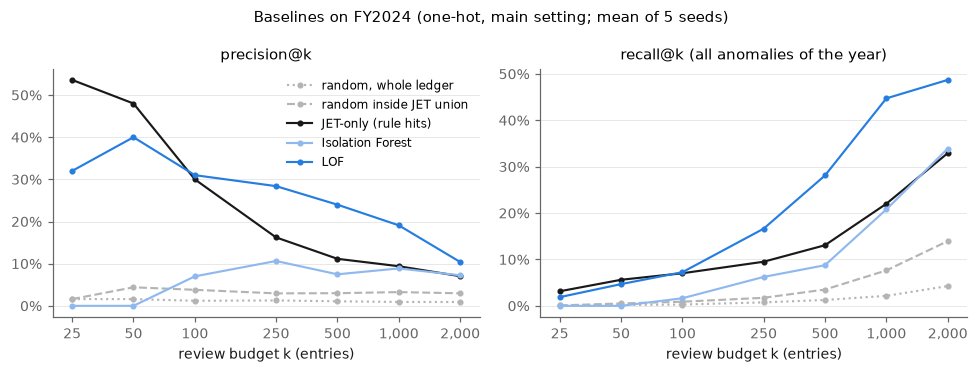

In [9]:
# cell_03_09
curves = pd.concat([m.summarise(results[(name, FY2)]).assign(method=name) for name in order], ignore_index=True)
fig = fg.fig_budget_curves(curves, "Baselines on FY2024 (one-hot, main setting; mean of 5 seeds)")
fg.save(fig, "bl_budget_curves_fy2024", FIG);

**Result (FY2024).**
- **Small budgets (k ≤ 50): JET-only is best** (P@25 = 53.6 % against LOF 32.0 %), because it reviews the few entries that hit three or four rules.
- **From k = 100 on, LOF is best** at every budget: P@250 = 28.4 % against 16.2 %, P@1000 = 19.1 % against 9.4 %; at k = 1,000 LOF finds 191 anomalies (recall 44.7 %) with 809 false positives, JET-only 94 (22.0 %) with 906. LOF also has the highest AP (0.144 against 0.092).
- **Isolation Forest is weak at the top** (no anomaly in its first 50 entries, P@100 = 7.0 %) and stays below JET-only up to k = 1,000 (AP 0.061). What it puts at the top is examined in notebook 09.

So neither the rules nor a model alone dominate: the rules are best for the first ~50 reviews, LOF afterwards. This is the gap the proposed approach (Step 4) addresses.

<div dir="rtl">

**نتیجه (FY2024).**
- **بودجه‌های کوچک (k ≤ 50): ‏JET-only بهترین است** (P@25 = 53.6٪ در برابر 32.0٪ برای LOF)، چون همان چند سندی را بررسی می‌کند که سه یا چهار قاعده را نقض می‌کنند.
- **از k = 100 به بعد LOF در همهٔ بودجه‌ها بهترین است**: ‏P@250 = 28.4٪ در برابر 16.2٪، ‏P@1000 = 19.1٪ در برابر 9.4٪؛ در k = 1,000 مدل LOF ‏191 ناهنجاری (recall ‏44.7٪) با 809 هشدار نادرست پیدا می‌کند و JET-only ‏94 (22.0٪) با 906. LOF بالاترین AP را هم دارد (0.144 در برابر 0.092).
- **Isolation Forest در بالای فهرست ضعیف است** (هیچ ناهنجاری در 50 سند اول، P@100 = 7.0٪) و تا k = 1,000 زیر JET-only می‌ماند (AP ‏0.061). اینکه چه چیزی را بالای فهرست می‌گذارد در notebook 09 بررسی می‌شود.

پس نه قاعده‌ها و نه یک مدل به‌تنهایی برتری کامل ندارند: قاعده‌ها برای حدود 50 بررسی اول بهترین‌اند و LOF پس از آن. روش پیشنهادی (Step 4) دقیقاً همین شکاف را هدف گرفته است.

</div>

## 7. Checks

### 7.1 The only four-line entry `p_2`

**Goal.** Notebook 02 (section 2) showed that `p_2` (FY2024, labelled normal) is the only entry that fills slot 4, and that its account 2020 occurs nowhere else. Both make it rare for a distance-based model. Where do the models rank it? (W5)

<div dir="rtl">

**هدف.** notebook 02 (بخش ۲) نشان داد `p_2` (‏FY2024، برچسب عادی) تنها سندی است که slot 4 را پر می‌کند و حساب 2020 آن جای دیگری نیامده. هر دو، آن را برای مدلی که بر فاصله تکیه دارد نادر می‌کنند. مدل‌ها آن را در چه رتبه‌ای می‌گذارند؟ (W5)

</div>

In [10]:
# cell_03_10
d2 = data[FY2]["meta"]
i_p2 = int(np.flatnonzero(d2["posting_id"].to_numpy() == "p_2")[0])
for detector, s in model_scores.items():
    rank = int((s > s[i_p2]).sum()) + 1          # 1 + number of entries with a higher score
    print(f"{detector}: p_2 ranks {rank:,} of {len(s):,}")

iforest: p_2 ranks 1,918 of 51,365
lof: p_2 ranks 212 of 51,365


**Result.** LOF ranks `p_2` 212th of 51,365 entries (within the budgets k = 250 and above); Isolation Forest 1,918th. LOF reacts to the rarity of the entry. Part of that rarity is an artefact of the fixed-slot encoding (slot 4), part is real content (prior-period expenses, of interest for cut-off testing), so an auditor might want to see this entry even though it is labelled normal (W5; discussed in Ch. 5).

<div dir="rtl">

**نتیجه.** ‏LOF سند `p_2` را در رتبهٔ 212 از 51,365 می‌گذارد (داخل بودجه‌های k = 250 و بالاتر)؛ Isolation Forest در رتبهٔ 1,918. LOF به نادر بودن سند واکنش نشان می‌دهد. بخشی از این نادر بودن اثر جانبی encoding با slot ثابت است (slot 4) و بخشی محتوای واقعی (هزینهٔ دورهٔ قبل، مهم برای آزمون cut-off)؛ پس بازبین ممکن است بخواهد این سند را با وجود برچسب «عادی» ببیند (W5؛ بحث در فصل ۵).

</div>

### 7.2 Anomalies inside and outside the JET union

**Goal.** A JET prefilter (Step 4 a) can only find anomalies inside the JET union. In FY2024, how many of the anomalies that each model puts in its first 1,000 entries lie outside the union — anomalies a prefilter would lose and the combined score (Step 4 b) could keep? (preview of RQ3)

<div dir="rtl">

**هدف.** فیلتر اولیهٔ JET (‏Step 4 a) فقط ناهنجاری‌های داخل اجتماع JET را می‌تواند پیدا کند. در FY2024 از ناهنجاری‌هایی که هر مدل در 1,000 سند اول خود می‌گذارد، چند تا بیرون اجتماع‌اند — ناهنجاری‌هایی که فیلتر اولیه از دست می‌دهد و امتیاز ترکیبی (‏Step 4 b) می‌تواند نگه دارد؟ (پیش‌نمایش RQ3)

</div>

In [11]:
# cell_03_11
k = data[FY2]["budgets"]["k1000"]
y2, jet2 = data[FY2]["y"].astype(bool), d2["jet_any"].to_numpy() == 1
print(f"FY2024: {y2.sum()} anomalies, {(y2 & jet2).sum()} inside the JET union, {(y2 & ~jet2).sum()} outside")
for detector, s in model_scores.items():
    top = m.review_order(s, 0)[:k]
    found = y2[top]
    print(f"{detector}: top {k:,} holds {found.sum()} anomalies — {(found & jet2[top]).sum()} inside the JET union, "
          f"{(found & ~jet2[top]).sum()} outside")

FY2024: 427 anomalies, 396 inside the JET union, 31 outside
iforest: top 1,000 holds 90 anomalies — 89 inside the JET union, 1 outside
lof: top 1,000 holds 191 anomalies — 168 inside the JET union, 23 outside


**Result.** FY2024 has 427 anomalies, 396 inside the JET union and 31 outside. Within its first 1,000 entries LOF finds 191 anomalies, **23 of them outside the JET union** — 23 of the 31 that a JET prefilter can never reach; Isolation Forest finds 1. A prefilter therefore gives up anomalies that a model alone finds; whether the combined score (Step 4 b) can keep them without losing the precision of the rules is RQ3 (notebook 07).

<div dir="rtl">

**نتیجه.** ‏FY2024 ‏427 ناهنجاری دارد: 396 داخل اجتماع JET و 31 بیرون. LOF در 1,000 سند اول خود 191 ناهنجاری پیدا می‌کند که **23 تای آن‌ها بیرون اجتماع JET‌اند** — 23 از همان 31 موردی که فیلتر اولیهٔ JET هرگز به آن‌ها نمی‌رسد؛ Isolation Forest فقط 1. پس فیلتر اولیه ناهنجاری‌هایی را از دست می‌دهد که یک مدل به‌تنهایی پیدا می‌کند؛ اینکه امتیاز ترکیبی (Step 4 b) بتواند آن‌ها را بدون از دست دادن دقت قاعده‌ها نگه دارد، پرسش RQ3 است (notebook 07).

</div>

## 8. Save the result table

**Goal.** Store every evaluated row of this notebook in one file, `results/03_baselines.csv`, overwritten on each run: method, detector, feature setting, hyperparameters, stage (no fitting / tuning / tuning (edge step) / report), fiscal year, seed and budget, with the metrics. Later notebooks (08) and the tables of Ch. 4 read this file.

<div dir="rtl">

**هدف.** همهٔ سطرهای ارزیابی‌شدهٔ این notebook در یک فایل ذخیره می‌شوند، `results/03_baselines.csv`، که در هر اجرا بازنویسی می‌شود: روش، detector، تنظیم ویژگی، هایپرپارامترها، مرحله (بدون fit / تنظیم / گام لبه / گزارش)، سال مالی، seed و بودجه، همراه با معیارها. notebook 08 و جدول‌های فصل ۴ از همین فایل می‌خوانند.

</div>

In [12]:
# cell_03_12
table = pd.concat(rows, ignore_index=True)
RESULTS.parent.mkdir(parents=True, exist_ok=True)
table.to_csv(RESULTS, index=False)
print("saved", RESULTS, table.shape)
table.groupby(["stage", "fy"]).size().rename("rows")

saved C:\MyWorks\Thesis\Jet\results\03_baselines.csv (560, 16)


stage               fy  
no fitting          2023    105
                    2024    105
report              2024     70
tuning              2023    210
tuning (edge step)  2023     70
Name: rows, dtype: int64

**Result.** `results/03_baselines.csv` holds 560 rows: the three rule orderings for both years (no fitting), the tuning and edge-step rows on FY2023, and the report rows on FY2024 (5 seeds × 7 budgets each). Rerunning the notebook overwrites the file.

## Notes for the thesis
- Ch. 3 (detectors, hyperparameters): grids, FY2023-only selection by mean AP, the edge rule (one step), and the identical-vector constraint on LOF k (D15, W15).
- Ch. 4 (baselines): the FY2024 comparison table and the budget figure `bl_budget_curves_fy2024`; JET-only best up to k = 50, LOF best from k = 100.
- Ch. 4 / RQ3: LOF finds 23 of the 31 anomalies outside the JET union within k = 1,000.
- Ch. 5: rank of `p_2` (W5).
- Notebook 05 adds the autoencoder, H1, H2 and the embedding encoding with the same functions.

<div dir="rtl">

**نتیجه.** ‏`results/03_baselines.csv` ‏560 سطر دارد: سه ترتیب قاعده‌ای برای هر دو سال (بدون fit)، سطرهای تنظیم و گام لبه روی FY2023، و سطرهای گزارش روی FY2024 (هر کدام 5 seed × 7 بودجه). اجرای دوبارهٔ notebook فایل را بازنویسی می‌کند.

</div>